## Exercise 2

For this exercise , you will be working with the [Titanic Data Set from Kaggle](https://www.kaggle.com/c/titanic). This is a very famous data set and very often is a student's first step in Data Analytics! 

The Dataset has been given to you on D2L. You need to download the .csv file from your assignment folder. The above link is just for a reference story about the data. 


1- For this assignment, you need to perform explorotary data analysis and answer at least three hypotheses based on the dataset. You may need to use your knowledge of statiscts to analyze this data.

Here are three possible hypotheses that you can define for this dataset (you can define your own hypotheses as well):

- Determine if the survival rate is associated to the class of passenger
- Determine if the survival rate is associated to the gender
- Determine the survival rate is associated to the age



2- For each hypothesis, you need to make at least one plot. 

3- Write a summary of your findings in one page (e.g., summary statistics, plots) and submit the pdf file. Therefore, for part 2 of your assignment, you need to submit one jupyter notebook file and one pdf file.

This will be your first end to end data analysis project. For this assignment, you will be graded on you overall analysis, and your final report.

4- Push your code and project to github and provide the link to your code here.



Ensure that your github project is organized to at least couple of main folders, ensure that you have the README file as well:

- Src
- Data
- Docs
- Results

Read this link for further info:  https://gist.github.com/ericmjl/27e50331f24db3e8f957d1fe7bbbe510

# Titanic Exploratory Data Analysis

## Objective

The purpose of this project is to perform Exploratory Data Analysis (EDA) on the Titanic dataset and investigate factors associated with passenger survival.

This analysis investigates three hypotheses:

1. Survival rate is associated with passenger class.
2. Survival rate is associated with gender.
3. Survival rate is associated with age.

In [10]:
import pandas as pd
import matplotlib.pyplot as plt

In [11]:
df = pd.read_csv("train.csv")

In [12]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [13]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 118.9 KB


In [15]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [16]:
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

## Hypothesis 1: Passenger Class and Survival

### Hypothesis

Passenger survival rate is associated with passenger class.

I will compare the survival rates of passengers in First, Second, and Third Class.

In [17]:
class_survival = df.groupby('Pclass')['Survived'].mean() * 100

class_survival

Pclass
1    62.962963
2    47.282609
3    24.236253
Name: Survived, dtype: float64

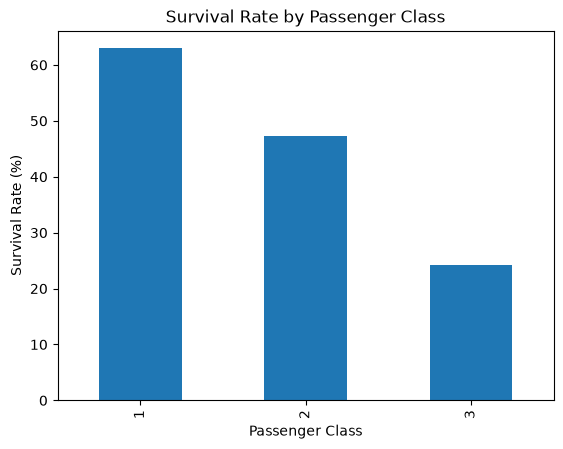

In [18]:
class_survival.plot(kind='bar')

plt.title('Survival Rate by Passenger Class')
plt.xlabel('Passenger Class')
plt.ylabel('Survival Rate (%)')

plt.show()

The analysis shows that survival rates differed across passenger classes. Passengers in higher classes generally had a higher survival rate than passengers in lower classes. Therefore, the data suggests an association between passenger class and survival.

## Hypothesis 2: Gender and Survival

### Hypothesis

Passenger survival rate is associated with gender.

I will compare the survival rates of male and female passengers.

In [20]:
gender_survival = df.groupby('Sex')['Survived'].mean() * 100

gender_survival

Sex
female    74.203822
male      18.890815
Name: Survived, dtype: float64

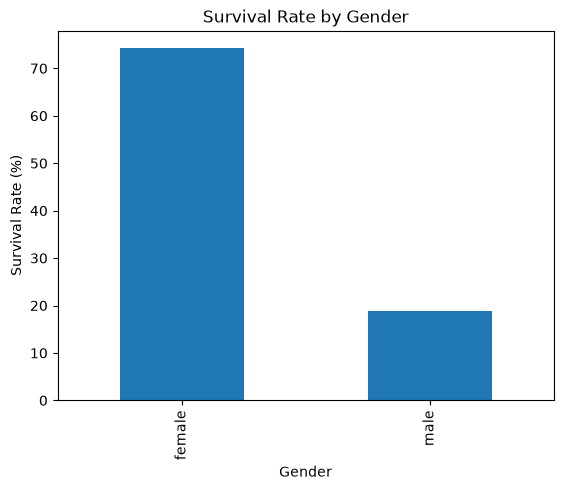

In [21]:
gender_survival.plot(kind='bar')

plt.title('Survival Rate by Gender')
plt.xlabel('Gender')
plt.ylabel('Survival Rate (%)')

plt.show()

You will likely find a significant difference between male and female survival rates.

## Hypothesis 3: Age and Survival

### Hypothesis


 Calculate the average age of passengers who survived and did not survive


In [22]:
df['Age'].describe()

count    714.000000
mean      29.699118
std       14.526497
min        0.420000
25%       20.125000
50%       28.000000
75%       38.000000
max       80.000000
Name: Age, dtype: float64

In [30]:
df['AgeGroup'] = pd.cut(
    df['Age'],
    bins=[0, 12, 18, 35, 60, 100],
    labels=['Child', 'Teen', 'Young Adult', 'Adult', 'Senior']
)

In [31]:
age_survival = df.groupby('AgeGroup', observed=False)['Survived'].mean() * 100
age_survival

AgeGroup
Child          57.971014
Teen           42.857143
Young Adult    38.268156
Adult          40.000000
Senior         22.727273
Name: Survived, dtype: float64

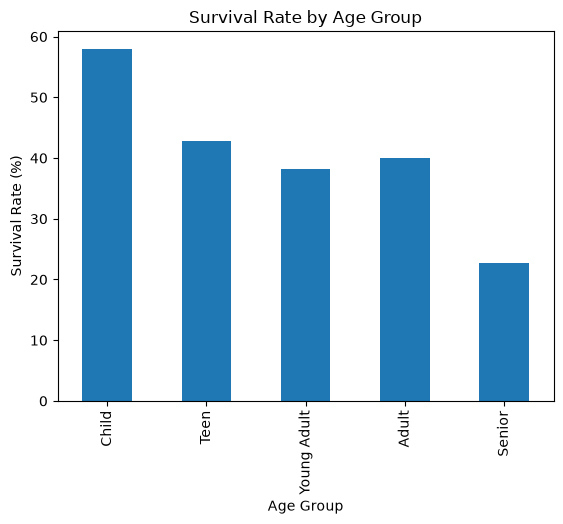

In [32]:
age_survival.plot(kind='bar')

plt.title('Survival Rate by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Survival Rate (%)')

plt.show()

The results suggest that age was associated with survival. Children had the highest survival rate at approximately 57.97%, while senior passengers had the lowest survival rate at approximately 22.73%. However, the relationship between age and survival was less straightforward than the relationships observed for gender and passenger class.

## Overall Conclusion

This exploratory data analysis investigated three factors associated with survival on the Titanic: passenger class, gender, and age.

The analysis found that passenger class was associated with survival. First-class passengers had the highest survival rate, while third-class passengers had the lowest survival rate.

Gender showed the strongest difference in survival rates. Female passengers had a substantially higher survival rate than male passengers.

Age also showed differences in survival patterns. Children had the highest survival rate among the age groups, while senior passengers had the lowest survival rate.

Overall, the results suggest that passenger class, gender, and age were all associated with survival. However, gender and passenger class showed clearer differences than age. These findings demonstrate associations in the dataset and do not necessarily establish causation.